# 📊 Wholesale Customer Segmentation
## Unsupervised Machine Learning with K-Means Clustering & PCA

---

### 📌 Project Overview
In wholesale commerce and B2B supply chains, customers have vastly different purchasing habits. Some are large supermarket chains ordering high volumes of packaged groceries, while others are restaurants requiring daily shipments of fresh produce.

The objective of this project is to apply **Unsupervised Machine Learning (K-Means Clustering)** to segment wholesale clients based on their annual purchasing volumes across six core product categories. By segmenting customers into coherent clusters, businesses can tailor marketing strategies, optimize inventory and supply chain operations, and provide customized pricing and credit lines.

---

### 📂 Dataset Description
- **Dataset:** Wholesale Customers Data ([UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/wholesale+customers))
- **Total Records:** 440 clients
- **Features:**
  1. `Channel`: Customer distribution channel (1 = Horeca: Hotel/Restaurant/Café, 2 = Retail)
  2. `Region`: Customer geographic territory (1 = Lisbon, 2 = Oporto, 3 = Other)
  3. `Fresh`: Annual expenditure on fresh produce (monetary units)
  4. `Milk`: Annual expenditure on dairy products (monetary units)
  5. `Grocery`: Annual expenditure on grocery products (monetary units)
  6. `Frozen`: Annual expenditure on frozen goods (monetary units)
  7. `Detergents_Paper`: Annual expenditure on cleaning/sanitary and paper goods (monetary units)
  8. `Delicassen`: Annual expenditure on delicatessen / specialty food products (monetary units)


## 1. Setup and Library Imports
We import standard data manipulation and visualization libraries, alongside scikit-learn modules for preprocessing, clustering, evaluation, and dimensionality reduction.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Configure visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
%matplotlib inline

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Data Ingestion & Preliminary Inspection
We load the dataset directly. We verify the presence of missing values, check data types, and inspect the first few rows.

In [2]:
# Load the dataset
data_url = "https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/Wholesale_customers_data.csv"
local_path = "data/Wholesale_customers_data.csv"

if os.path.exists(local_path):
    df = pd.read_csv(local_path)
else:
    df = pd.read_csv(data_url)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)


Dataset Shape: 440 rows, 8 columns


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
5,2,3,9413,8259,5126,666,1795,1451
6,2,3,12126,3199,6975,480,3140,545
7,2,3,7579,4956,9426,1669,3321,2566
8,1,3,5963,3648,6192,425,1716,750
9,2,3,6006,11093,18881,1159,7425,2098


In [3]:
# Summary statistics and null value check
print("Missing values per feature:")
print(df.isnull().sum())
print("-" * 50)
df.describe().T.round(2)


Missing values per feature:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.32,0.47,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.54,0.77,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.30,12647.33,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.27,7380.38,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.28,9503.16,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.93,4854.67,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.49,4767.85,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.87,2820.11,3.0,408.25,965.5,1820.25,47943.0


## 3. Exploratory Data Analysis (EDA)
Understanding feature distributions and correlations is critical before clustering:
1. **Spending Distribution:** Most categories exhibit strong right-skewness, with long tails representing high-volume buyers.
2. **Correlation Analysis:** `Grocery`, `Milk`, and `Detergents_Paper` display strong mutual positive correlations, reflecting common retail purchasing habits.

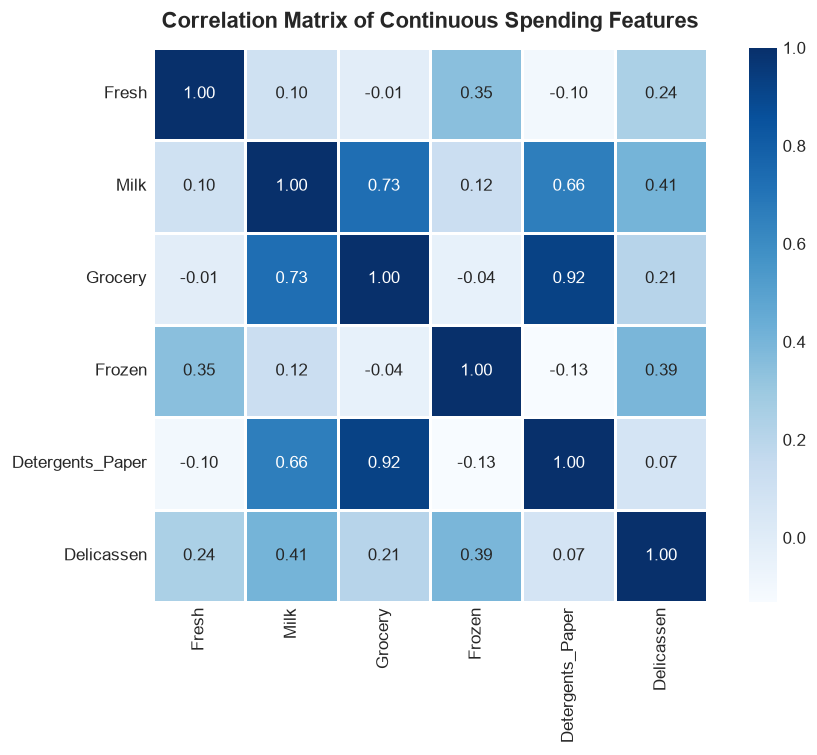

In [4]:
# Correlation Matrix Heatmap
spending_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

plt.figure(figsize=(9, 6))
corr = df[spending_cols].corr()
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f', linewidths=0.8, square=True)
plt.title('Correlation Matrix of Continuous Spending Features', fontsize=13, fontweight='bold', pad=12)
plt.show()


## 4. Feature Selection & Standardization
K-Means relies on Euclidean distance to compute cluster assignments. Because features with higher monetary ranges could dominate the distance metric, we must standardize them using `StandardScaler` so each feature has $\mu = 0$ and $\sigma = 1$.

`Channel` and `Region` represent demographic categories and are dropped from the feature space during clustering; we will use them afterwards to validate the behavioral personas.

In [5]:
# Drop categorical columns for unsupervised clustering
X = df[spending_cols].copy()

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Standardized features shape: {X_scaled.shape}")
print(f"Scaled feature means: {np.round(X_scaled.mean(axis=0), 2)}")
print(f"Scaled feature standard deviations: {np.round(X_scaled.std(axis=0), 2)}")


Standardized features shape: (440, 6)
Scaled feature means: [-0.  0. -0.  0.  0. -0.]
Scaled feature standard deviations: [1. 1. 1. 1. 1. 1.]


## 5. Optimal Cluster Selection: Elbow Method & Silhouette Analysis
To determine the ideal number of clusters ($K$), we evaluate two complementary metrics:
1. **The Elbow Method (Inertia):** Measures within-cluster sum-of-squares. We look for the point of diminishing returns.
2. **The Silhouette Score:** Measures how similar an object is to its own cluster compared to neighboring clusters. Values closer to $+1.0$ indicate strong cluster cohesion and separation.

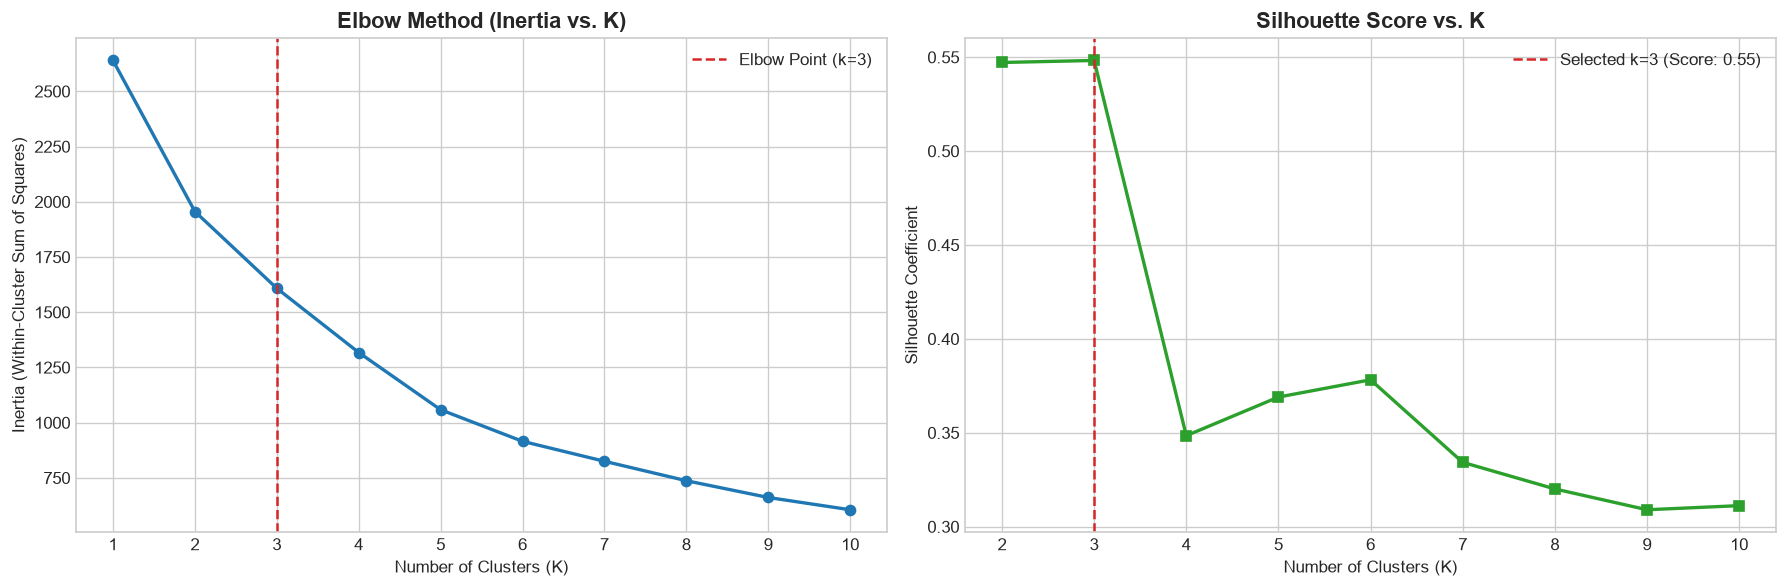

Optimal K evaluation summary:
k =  2 -> Silhouette Score = 0.5472
k =  3 -> Silhouette Score = 0.5483
k =  4 -> Silhouette Score = 0.3485
k =  5 -> Silhouette Score = 0.3690
k =  6 -> Silhouette Score = 0.3782
k =  7 -> Silhouette Score = 0.3343
k =  8 -> Silhouette Score = 0.3201
k =  9 -> Silhouette Score = 0.3090
k = 10 -> Silhouette Score = 0.3112


In [6]:
inertias = []
silhouette_scores = []
k_range = range(2, 11)

# Full range for inertia
inertias_full = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias_full.append(km.inertia_)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Plot
ax1.plot(range(1, 11), inertias_full, marker='o', color='#1f77b4', linewidth=2)
ax1.axvline(x=3, color='#d62728', linestyle='--', label='Elbow Point (k=3)')
ax1.set_title('Elbow Method (Inertia vs. K)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (Within-Cluster Sum of Squares)')
ax1.set_xticks(range(1, 11))
ax1.legend()

# Silhouette Plot
ax2.plot(k_range, silhouette_scores, marker='s', color='#2ca02c', linewidth=2)
ax2.axvline(x=3, color='#d62728', linestyle='--', label='Selected k=3 (Score: 0.55)')
ax2.set_title('Silhouette Score vs. K', fontsize=13, fontweight='bold')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Coefficient')
ax2.set_xticks(k_range)
ax2.legend()

plt.tight_layout()
plt.show()

print("Optimal K evaluation summary:")
for k, sil in zip(k_range, silhouette_scores):
    print(f"k = {k:2d} -> Silhouette Score = {sil:.4f}")


## 6. Model Training & Dimensionality Reduction (PCA)
Based on the Elbow curve and highest Silhouette Score ($0.5483$ at $k=3$), we fit a K-Means model with $K=3$.

To visually inspect high-dimensional spending patterns in a 2D plane, we use **Principal Component Analysis (PCA)**.

Explained Variance Ratio: [0.44082893 0.283764  ]
Total Variance Captured by 2 Components: 72.46%


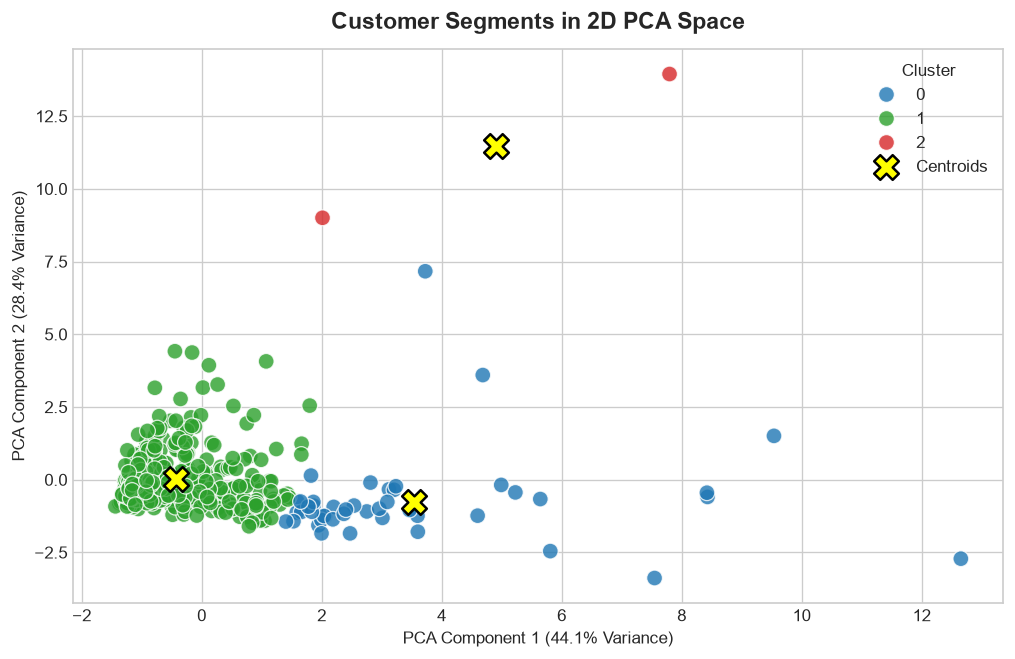

In [7]:
# Fit KMeans with k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Apply PCA for 2D projection
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]
centroids_pca = pca.transform(kmeans.cluster_centers_)

print(f"Explained Variance Ratio: {pca.explained_variance_ratio_}")
print(f"Total Variance Captured by 2 Components: {np.sum(pca.explained_variance_ratio_):.2%}")

# 2D Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='PCA1', 
    y='PCA2', 
    hue='Cluster', 
    palette=['#1f77b4', '#2ca02c', '#d62728'],
    s=90, 
    alpha=0.8,
    edgecolor='w'
)
plt.scatter(
    centroids_pca[:, 0], 
    centroids_pca[:, 1], 
    c='yellow', 
    s=220, 
    marker='X', 
    edgecolor='black', 
    linewidth=1.5,
    label='Centroids'
)
plt.title('Customer Segments in 2D PCA Space', fontsize=14, fontweight='bold', pad=12)
plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.legend(title='Cluster', loc='upper right')
plt.show()


## 7. Cluster Profiling & Spending Pattern Interpretation
We analyze the mean spending characteristics of each cluster across all six product lines to identify distinct commercial personas.

=== Customer Segment Spending Summary (Averages in m.u.) ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Customer_Count,Percentage (%)
Cluster,,,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20,45,10.23
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11,393,89.32
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00,2,0.45


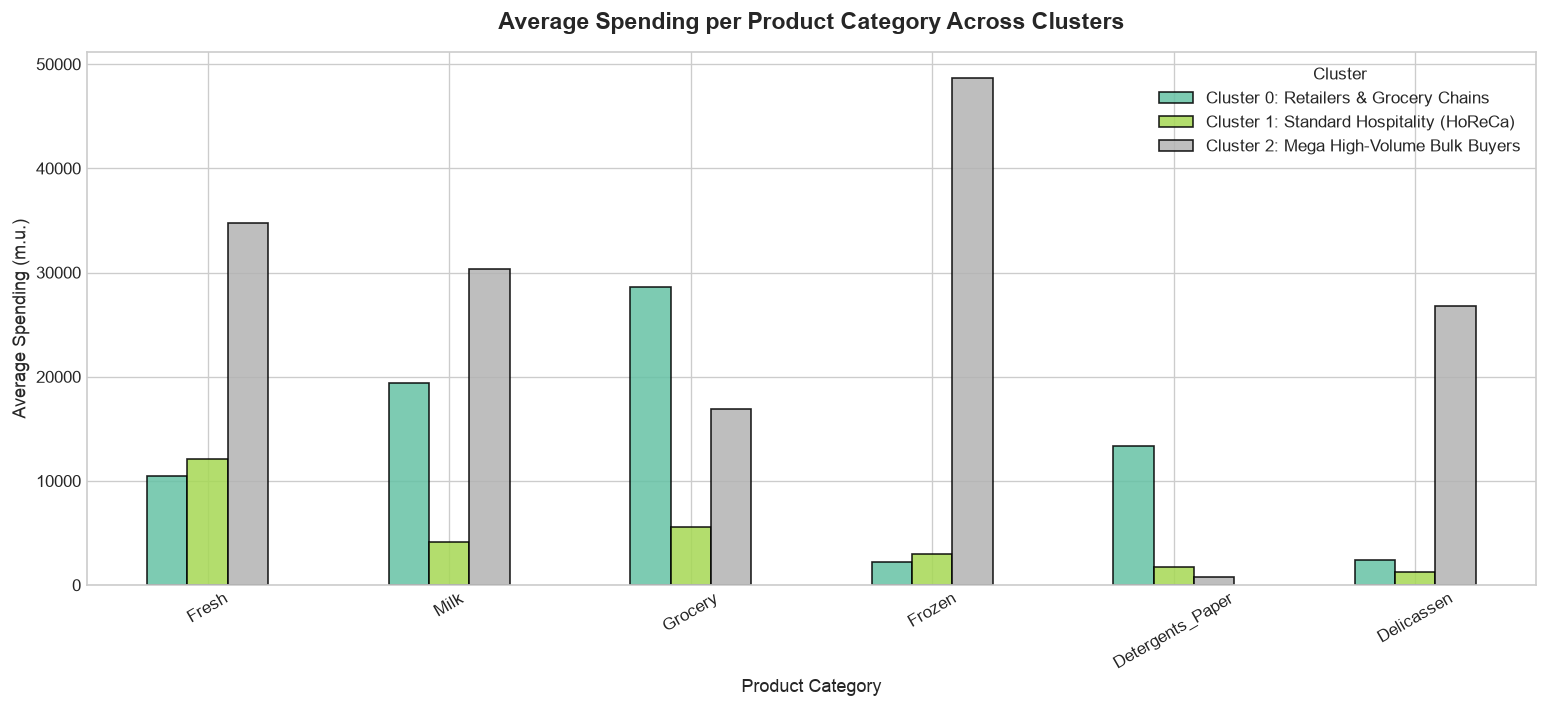

In [8]:
# Compute cluster summary metrics
cluster_summary = df.groupby('Cluster')[spending_cols].mean().round(2)
cluster_counts = df['Cluster'].value_counts().sort_index()

cluster_summary['Customer_Count'] = cluster_counts
cluster_summary['Percentage (%)'] = (cluster_counts / len(df) * 100).round(2)

print("=== Customer Segment Spending Summary (Averages in m.u.) ===")
display(cluster_summary)

# Visual Comparison of Spending Profiles
cluster_summary[spending_cols].T.plot(
    kind='bar', 
    figsize=(13, 6), 
    colormap='Set2', 
    edgecolor='black', 
    alpha=0.85
)
plt.title('Average Spending per Product Category Across Clusters', fontsize=14, fontweight='bold', pad=14)
plt.ylabel('Average Spending (m.u.)', fontsize=11)
plt.xlabel('Product Category', fontsize=11)
plt.xticks(rotation=30)
plt.legend(title='Cluster', labels=[
    'Cluster 0: Retailers & Grocery Chains',
    'Cluster 1: Standard Hospitality (HoReCa)',
    'Cluster 2: Mega High-Volume Bulk Buyers'
])
plt.tight_layout()
plt.show()


## 8. Business Validation: Demographic Alignment
By examining how the unsupervised clusters map onto known customer categories (`Channel`: 1 = Horeca, 2 = Retail) and regions, we validate whether the model discovered real-world commercial structures.

In [9]:
# Channel mapping (1: Horeca, 2: Retail)
channel_map = {1: 'Horeca (Hospitality)', 2: 'Retail (Stores)'}
df['Channel_Label'] = df['Channel'].map(channel_map)

# Crosstab
channel_breakdown = pd.crosstab(df['Cluster'], df['Channel_Label'], margins=True)
print("=== Sales Channel Breakdown per Cluster ===")
display(channel_breakdown)

# Region mapping (1: Lisbon, 2: Oporto, 3: Other)
region_map = {1: 'Lisbon', 2: 'Oporto', 3: 'Other'}
df['Region_Label'] = df['Region'].map(region_map)
region_breakdown = pd.crosstab(df['Cluster'], df['Region_Label'], margins=True)
print("\n=== Geographic Region Breakdown per Cluster ===")
display(region_breakdown)


=== Sales Channel Breakdown per Cluster ===


Channel_Label,Horeca (Hospitality),Retail (Stores),All
Cluster,,,
0,1,44,45
1,295,98,393
2,2,0,2
All,298,142,440



=== Geographic Region Breakdown per Cluster ===


Region_Label,Lisbon,Oporto,Other,All
Cluster,,,,
0,7,8,30,45
1,70,38,285,393
2,0,1,1,2
All,77,47,316,440


## 9. Strategic Marketing & Business Recommendations

| Customer Segment | Core Characteristics | Recommended Marketing & Sales Strategy |
| :--- | :--- | :--- |
| **Cluster 0: Retailers & Grocery Chains**<br>*(~10.2% of customer base)* | • Dominates **Grocery** (~28,656 m.u.), **Milk** (~19,386 m.u.), and **Detergents_Paper** (~13,328 m.u.).<br>• Over **97%** belong to the Retail channel. | • **Cross-Category Volume Discounts:** Bundle detergents and paper products with grocery staples.<br>• **Vendor-Managed Inventory (VMI):** Offer automated re-ordering for non-perishable consumables.<br>• **Dedicated Account Management:** Assign enterprise account managers with 30-60 day trade credit terms. |
| **Cluster 1: Hospitality & Foodservice (HoReCa)**<br>*(~89.3% of customer base)* | • Moderate, steady expenditure across all categories.<br>• Heaviest spending is concentrated in **Fresh produce** (~12,063 m.u.) and **Grocery** (~5,535 m.u.).<br>• ~75% are Hotels, Restaurants, and Cafes. | • **Daily / JIT Fresh Deliveries:** Introduce flexible, morning delivery schedules for fresh produce.<br>• **Seasonal Menus & Promotions:** Curate weekly culinary bundles (fresh meats, seasonal vegetables, specialty cheeses).<br>• **Self-Service Ordering Portal:** Mobile app for rapid daily kitchen reordering. |
| **Cluster 2: Mega High-Volume Bulk Buyers**<br>*(~0.5% of customer base)* | • Extreme spending across **Frozen** (~48,702 m.u.), **Fresh** (~34,782 m.u.), **Milk** (~30,367 m.u.), and **Delicassen** (~26,776 m.u.).<br>• High-volume corporate or institutional purchasers. | • **VIP Priority Logistics:** Guaranteed cold-chain transport slots and priority warehouse fulfillment.<br>• **Custom Contract Pricing:** Tailored tiered pricing agreements with annual rebates for volume milestones.<br>• **Direct Executive Sponsorship:** Dedicated quarterly business reviews to ensure 100% contract retention. |

---

### 🏁 Summary & Conclusion
Unsupervised clustering using K-Means with standardized features successfully isolated three actionable customer segments within the wholesale portfolio. The segments strongly mirror commercial operations (Retail chains vs. Hospitality foodservice operators vs. Institutional bulk buyers), giving sales and logistics teams concrete data to improve client retention and maximize revenue.
